# Tugas Association Rule - Online Retail
Sulaiman Faiz Tsaqib - 5054251048

## 1. Import Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import fpgrowth, association_rules

df = pd.read_excel("Online Retail.xlsx")
display(df.head())
print(df.shape)
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


(541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. Pembersihan Data
Kolom relevan: `InvoiceNo` (ID transaksi) dan `Description` (nama produk).

In [2]:
before = (len(df), df.InvoiceNo.nunique())
print("Missing Description:", df.Description.isna().sum())
print("Invoice dibatalkan (C):", df.InvoiceNo.astype(str).str.startswith("C").sum())
print("Quantity <= 0:", (df.Quantity <= 0).sum())

df = df.dropna(subset=["Description"])
df = df[~df.InvoiceNo.astype(str).str.startswith("C") & (df.Quantity > 0)].copy()
df["Description"] = df.Description.str.strip()

after = (len(df), df.InvoiceNo.nunique())
pd.DataFrame({"Sebelum": before, "Sesudah": after}, index=["Jumlah baris", "Jumlah invoice"])

Missing Description: 1454


Invoice dibatalkan (C): 9288
Quantity <= 0: 10624


,Sebelum,Sesudah
Jumlah baris,541909,530693
Jumlah invoice,25900,20136


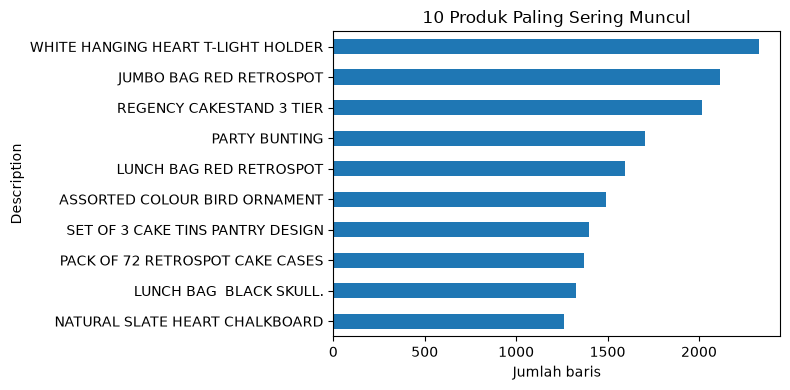

In [3]:
top = df.Description.value_counts().head(10)
top[::-1].plot.barh(title="10 Produk Paling Sering Muncul", figsize=(8, 4))
plt.xlabel("Jumlah baris"); plt.tight_layout(); plt.show()

## 3. Format Transaksi (One-Hot Basket)
Satu baris = satu invoice, satu kolom = satu produk (True/False).

In [4]:
basket = df.groupby(["InvoiceNo", "Description"]).size().unstack(fill_value=0).gt(0)
print(basket.shape)

(20136, 4065)


## 4. Algoritma FP-Growth
Mulai dengan min support 0.01 dan min confidence 0.5.

In [5]:
itemsets = fpgrowth(basket, min_support=0.01, use_colnames=True)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.5)
print("Frequent itemset:", len(itemsets), "| Aturan:", len(rules))

Frequent itemset: 1853 | Aturan: 841


## 5. Evaluasi Aturan

In [6]:
cols = ["antecedents", "consequents", "support", "confidence", "lift"]
fmt = lambda r: r.assign(antecedents=r.antecedents.map(", ".join), consequents=r.consequents.map(", ".join))[cols]
ranked = rules.sort_values("lift", ascending=False)
display(fmt(ranked.head(10)).round(3))

# aturan simetris (A->B, B->A) punya lift sama: ambil 1 per pasangan, hanya aturan 1 item -> 1 item
ranked = ranked[(ranked.antecedents.map(len) == 1) & (ranked.consequents.map(len) == 1)]
ranked = ranked.assign(pair=ranked.apply(lambda r: r.antecedents | r.consequents, axis=1)).drop_duplicates("pair")
print("Top 3 lift:")
display(fmt(ranked.head(3)).round(3))
print("Top 3 lift di luar HERB MARKER:")
display(fmt(ranked[~ranked.pair.map(lambda p: any("HERB MARKER" in i for i in p))].head(3)).round(3))

,antecedents,consequents,support,confidence,lift
374,HERB MARKER THYME,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",0.010,0.857,80.220
371,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",HERB MARKER THYME,0.010,0.944,80.220
373,HERB MARKER ROSEMARY,"HERB MARKER THYME, HERB MARKER PARSLEY",0.010,0.846,79.961
372,"HERB MARKER THYME, HERB MARKER PARSLEY",HERB MARKER ROSEMARY,0.010,0.953,79.961
363,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011,0.932,78.236
362,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011,0.921,78.236
375,HERB MARKER PARSLEY,"HERB MARKER ROSEMARY, HERB MARKER THYME",0.010,0.853,77.714
370,"HERB MARKER ROSEMARY, HERB MARKER THYME",HERB MARKER PARSLEY,0.010,0.919,77.714
364,HERB MARKER THYME,HERB MARKER PARSLEY,0.011,0.899,76.037
365,HERB MARKER PARSLEY,HERB MARKER THYME,0.011,0.895,76.037


Top 3 lift:


,antecedents,consequents,support,confidence,lift
363,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011,0.932,78.236
364,HERB MARKER THYME,HERB MARKER PARSLEY,0.011,0.899,76.037
356,HERB MARKER ROSEMARY,HERB MARKER PARSLEY,0.011,0.896,75.792


Top 3 lift di luar HERB MARKER:


,antecedents,consequents,support,confidence,lift
807,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK,0.014,0.730,48.172
825,SET OF 3 WOODEN STOCKING DECORATION,SET OF 3 WOODEN TREE DECORATIONS,0.011,0.687,47.180
802,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.012,0.755,46.188


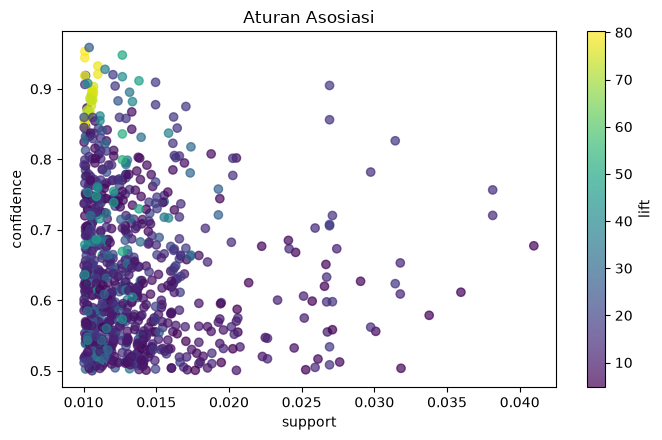

In [7]:
plt.figure(figsize=(7, 4.5))
sc = plt.scatter(rules.support, rules.confidence, c=rules.lift, cmap="viridis", alpha=.7)
plt.colorbar(sc, label="lift"); plt.xlabel("support"); plt.ylabel("confidence")
plt.title("Aturan Asosiasi"); plt.tight_layout(); plt.show()

## 6. Laporan Singkat

### 6.1 Eksplorasi dan Pembersihan Data
| | Sebelum | Sesudah |
|---|---|---|
| Jumlah baris | 541.909 | 530.693 |
| Jumlah invoice | 25.900 | 20.136 |

- Dihapus: 1.454 baris `Description` kosong, 9.288 baris invoice batal (awalan "C"), dan baris `Quantity` <= 0.
- Hasil one-hot: 20.136 transaksi x 4.065 produk.

### 6.2 Aturan Asosiasi
- Algoritma FP-Growth, min support 0.01, min confidence 0.5 -> 1.853 frequent itemset dan 841 aturan.
- Jumlah aturan wajar (tidak terlalu sedikit/banyak), jadi parameter awal **tidak diubah**. Support 0.02 hanya menghasilkan 61 aturan (terlalu sedikit).

**Tiga aturan terbaik berdasarkan lift** (aturan simetris A->B dan B->A dihitung satu):

| Antecedent | Consequent | Support | Confidence | Lift |
|---|---|---|---|---|
| HERB MARKER THYME | HERB MARKER ROSEMARY | 0.011 | 0.932 | 78.2 |
| HERB MARKER THYME | HERB MARKER PARSLEY | 0.011 | 0.899 | 76.0 |
| HERB MARKER ROSEMARY | HERB MARKER PARSLEY | 0.011 | 0.896 | 75.8 |

**Interpretasi bisnis:**
- Ketiganya satu keluarga produk (set penanda tanaman herbal). Pembeli thyme hampir pasti (90-93%) juga membeli rosemary/parsley; lift ~76-78 berarti peluang beli bersamaan ~76-78x lebih besar daripada kebetulan. Rekomendasi: jual sebagai bundle satu set lengkap dan letakkan berdekatan.
- Di luar kelompok herb, aturan terkuat: *REGENCY TEA PLATE GREEN -> PINK* (lift 48.2), *SET OF 3 WOODEN STOCKING DECORATION -> TREE DECORATIONS* (lift 47.2), *REGENCY SUGAR BOWL GREEN -> MILK JUG PINK* (lift 46.2). Pola: pelanggan (kemungkinan grosir) melengkapi satu koleksi/warna sehingga cocok untuk paket koleksi atau rekomendasi "lengkapi set".
- Support rendah (~1%) berarti pola berlaku untuk segmen kecil, tetapi sangat dapat diandalkan (confidence tinggi).

### 6.3 Kesimpulan
- Pembersihan menghapus ~2% baris dan ~22% invoice (terutama pembatalan).
- Pola dominan adalah pembelian produk berseri/sekoleksi (varian warna atau item pelengkap), bukan lintas kategori.
- Lift sangat tinggi karena produk-produk tersebut jarang dibeli sendiri; hasil dapat dipakai untuk bundling, penataan produk, dan rekomendasi.